# Task 1b: Variation across sessions and replicates, and data limitations

**Owner:** account 2

Looks at how a writer's digits change between sessions and within a session, and lists
limitations of the simulated data.

In [1]:
import sys
sys.path.append("../src")  # so the notebook can import our own modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_utils import load_handwriting, select
from eda_plots import show_grid, show_mean_images, image_features

images, meta = load_handwriting()  # pixels scaled to [0, 1]

In [2]:
features = pd.concat([meta, pd.DataFrame(image_features(images))], axis=1)

## 1. The same digit across sessions (digit 2, replicate 1)

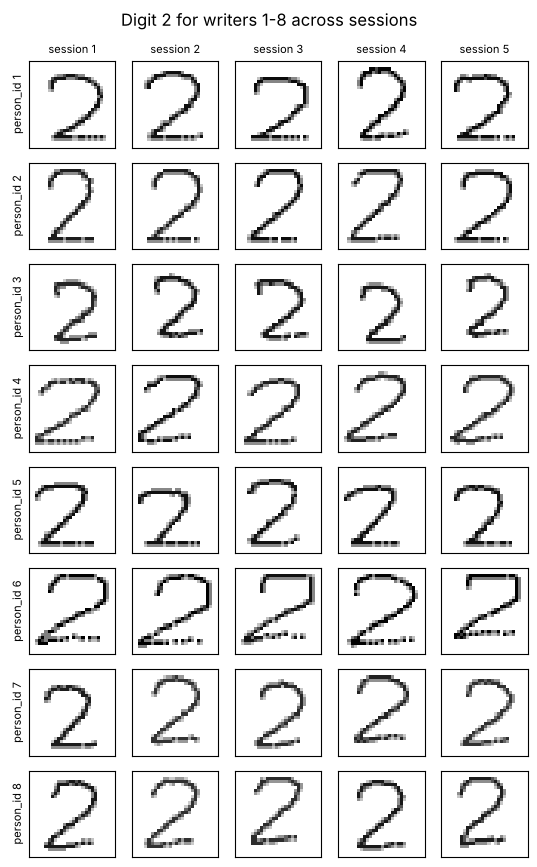

In [3]:
fig = show_grid(images, meta, row_var="person_id", col_var="session",
                row_values=range(1, 9), col_values=range(1, 6),
                fixed={"digit": 2}, title="Digit 2 for writers 1-8 across sessions")
plt.show()

## 2. Replicates within one session (writer 1, digit 3)

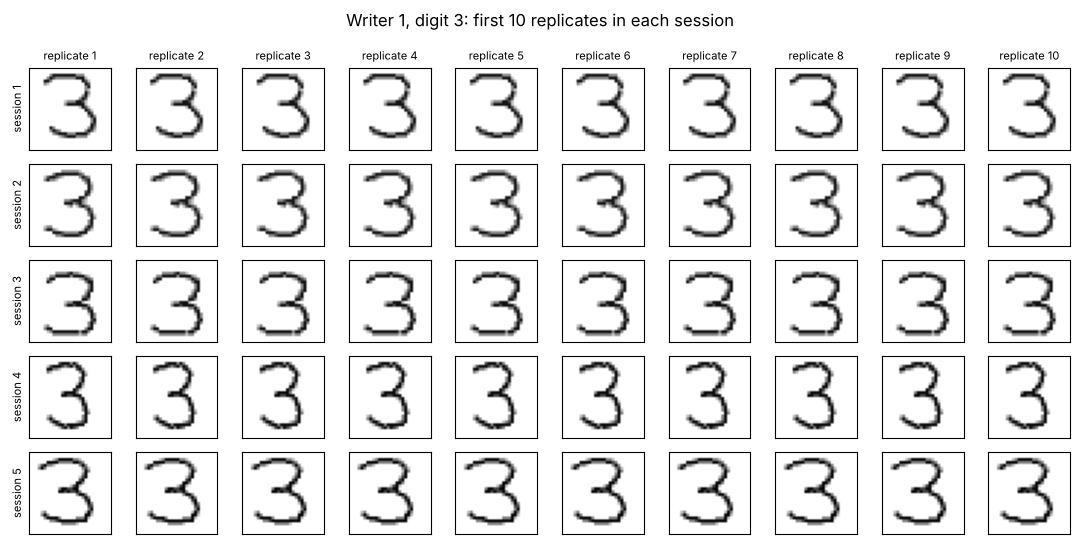

In [4]:
fig = show_grid(images, meta, row_var="session", col_var="replicate",
                row_values=range(1, 6), col_values=range(1, 11),
                fixed={"person_id": 1, "digit": 3},
                title="Writer 1, digit 3: first 10 replicates in each session")
plt.show()

## 3. How much does each measurement change between sessions?

Each line is one writer. Flat lines = the writer is stable across sessions.

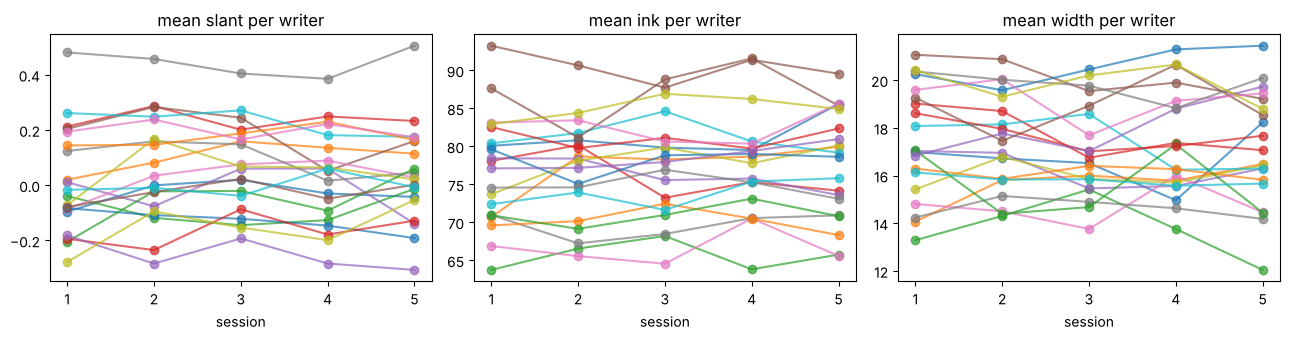

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["slant", "ink", "width"]):
    table = features.pivot_table(index="session", columns="person_id", values=col)
    table.plot(ax=ax, legend=False, marker="o", alpha=0.7)
    ax.set_title(f"mean {col} per writer")
    ax.set_xticks(range(1, 6))
plt.tight_layout()
plt.show()

In [6]:
# Share of the variation in each measurement explained by different groupings.
# 1.0 = the grouping explains everything; the 'within session' column is what is left
# over between the 50 replicates of the same writer, digit and session.
rows = []
for col in ["ink", "width", "height", "slant", "x_centre", "y_centre"]:
    total = features[col].var()
    def explained(groups):
        return features.groupby(groups)[col].transform("mean").var() / total
    cell_mean = features.groupby(["person_id", "digit", "session"])[col].transform("mean")
    rows.append({
        "measurement": col,
        "digit": explained(["digit"]),
        "writer + digit": explained(["person_id", "digit"]),
        "writer + digit + session": explained(["person_id", "digit", "session"]),
        "within session (left over)": ((features[col] - cell_mean) ** 2).mean() / total,
    })
pd.DataFrame(rows).set_index("measurement").round(2)

,digit,writer + digit,writer + digit + session,within session (left over)
measurement,,,,
ink,0.40,0.90,0.95,0.05
width,0.42,0.88,0.97,0.03
height,0.16,0.71,0.87,0.13
slant,0.10,0.90,1.00,0.00
x_centre,0.32,0.80,1.00,0.00
y_centre,0.15,0.59,0.99,0.01


## 4. Pixel distance between pairs of images (same digit)

Compares three kinds of pairs: two replicates from the same session, the same writer in
different sessions, and two different writers. This matters for the train/test split (Task 4)
and for building Siamese pairs (Task 3).

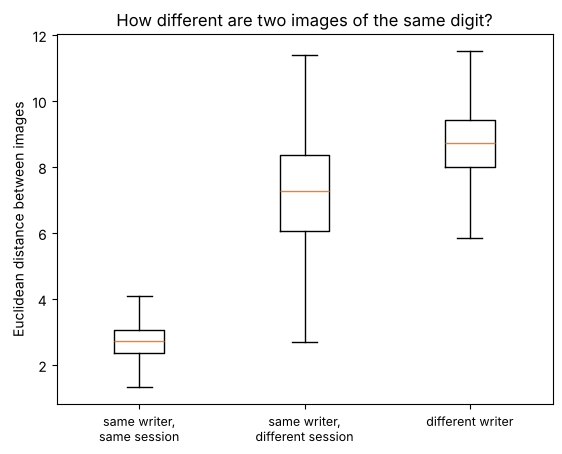

,"same writer, same session","same writer, different session",different writer
25%,2.37,6.07,7.99
50%,2.74,7.28,8.73
75%,3.06,8.36,9.43


In [7]:
X = images.reshape(len(images), -1)
person, digit, session = meta.person_id.values, meta.digit.values, meta.session.values
all_idx = np.arange(len(X))
rng = np.random.default_rng(1)

pair_types = {"same writer, same session": [],
              "same writer, different session": [],
              "different writer": []}
for _ in range(5000):
    i = rng.integers(len(X))
    same_digit = digit == digit[i]
    candidates = {
        "same writer, same session": same_digit & (person == person[i]) & (session == session[i]) & (all_idx != i),
        "same writer, different session": same_digit & (person == person[i]) & (session != session[i]),
        "different writer": same_digit & (person != person[i]),
    }
    for name, mask in candidates.items():
        j = rng.choice(all_idx[mask])
        pair_types[name].append(np.linalg.norm(X[i] - X[j]))

plt.boxplot(list(pair_types.values()), showfliers=False)
plt.xticks([1, 2, 3], [name.replace(", ", ",\n") for name in pair_types], fontsize=9)
plt.ylabel("Euclidean distance between images")
plt.title("How different are two images of the same digit?")
plt.show()

pd.DataFrame(pair_types).describe().loc[["25%", "50%", "75%"]].round(2)

## 5. Limitations of the simulated data (to discuss in the report)

Starting points to check against the plots above and put in your own words:

- Only digits 0-4 and 20 writers; perfectly balanced (50 per cell), unlike real data.
- Images are simulated: strokes look like dotted/stamped pen paths on a clean background,
  with no paper texture, scanning noise, or touching/broken digits.
- Replicates within a session look very similar to each other. Compare the three distances
  above: what does this mean for a random train/test split?
- Session changes seem to shift a writer's whole style (slant, size, thickness) at once.
  Is that realistic?
- The simulation settings are unknown, so a model may learn the generator's rules rather
  than real handwriting traits.